<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/code/01RAD_Ex08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Exercise 08: Outliers, Influential Observations and Robust Regression

Model $(\ast\ast)$: $\mathbf{Y} = \mathbf{X}\boldsymbol{\beta} + \mathbf{e}$, $h(\mathbf{X}) = m+1$, $\mathbf{e} \sim N_n(\mathbf{0}, \sigma^2\mathbf{I}_n)$. Slides `lectures/01RAD_2024.pdf`, pp. 119–132; the lecture will go through them after this exercise, the formulas needed here are stated in the text:
- **PRESS residuals** (PRESS rezidua, deleted residuals), Theorems 4.1–4.3, Corollary 4.1, pp. 119–124,
- **test of an outlier** (test odlehlého pozorování), Statement 4.1, Remarks 4.4–4.7, pp. 125–127,
- **influence measures** (míry influence): **DFBETAS**, **Cook's distance** (Cookova vzdálenost), **DFFITS**, Remarks 4.8–4.10, pp. 128–132.

**Robust regression** (robustní regrese: M-estimators, LTS) is not in the lecture; it is the alternative to deleting points.

R equivalents in brackets.

## Learning goals
- PRESS residual $\widehat{e}_{(-i)} = \widehat{e}_i/(1-h_{ii})$: the prediction error for a point the model did not see, without refitting.
- Test of an outlier with $\widehat{t}_i \sim t(n-m-2)$; why it needs a correction for multiple testing (Bonferroni).
- DFBETAS, Cook's distance, DFFITS: what each measures, their rules of thumb, and why "large residual" and "large leverage" are not enough on their own.
- Single-case deletion fails for a group of similar points (**masking**).
- M-estimators (Huber, Tukey) protect against outliers in $y$, LTS also against bad leverage points; the weights of a robust fit are a diagnostic.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import warnings

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.precision', 4)
pd.set_option('display.max_columns', 20)
np.set_printoptions(precision=4, suppress=True)

In [2]:
base = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/'

# Examples 3.2-3.4 and 4.2 of the slides: birth weight (g) and gestational age (weeks)
birth = pd.DataFrame({
    'Weight': [2968, 2795, 3163, 2925, 2625, 2847, 3292, 3473, 2628, 3176, 3421, 2975,
               3317, 2729, 2935, 2754, 3210, 2817, 3126, 2539, 2412, 2991, 2875, 3231],
    'Age': [40, 38, 40, 35, 36, 37, 41, 40, 37, 38, 40, 38, 40, 36, 40, 38, 42, 39, 40, 37, 36, 38, 39, 40],
    'Sex': ['boy'] * 12 + ['girl'] * 12})

# 2004 cars, cleaned as in Exercise 07, Section 2 (L/100 km, hybrids removed, drive codes fixed)
cars04 = pd.read_csv(base + 'carsdata2.csv', sep=';')
types = ['Sedan', 'Sports', 'SUV', 'Wagon', 'Minivan', 'Pickup']
cars04['type'] = cars04[types].idxmax(axis=1)
cars04['drive'] = np.select([cars04['AWD'] == 1, cars04['RWD'] == 1], ['AWD', 'RWD'], 'FWD')
cars04.loc[cars04['Name'].str.contains('RS 6|4MOTION'), 'drive'] = 'AWD'
cars04.loc[cars04['Name'].str.contains('Armada'), 'drive'] = 'RWD'
cars04['consumption'] = 235.215 / ((cars04['CityMPG'] + cars04['HwyMPG']) / 2)      # L/100 km
used = ['consumption', 'Weight', 'HP', 'EngineSize', 'type', 'drive']
d04 = cars04[~cars04['Name'].str.contains('gas/electric')].dropna(subset=used).reset_index(drop=True)

# Sarasota houses (HW04, Exercise 07), without the 2 houses with no price
houses = pd.read_csv(base + 'sarasota_houses_mod.csv').dropna(subset=['price']).reset_index(drop=True)

# star cluster CYG OB1 (R: robustbase::starsCYG): log surface temperature and log light intensity of 47 stars
stars = pd.read_csv(base + 'STARS.txt', sep=r'\s+', header=None, names=['star', 'log_Te', 'log_light'])
print(f'{len(birth)} newborns, {len(d04)} cars of 2004, {len(houses)} houses, {len(stars)} stars')

24 newborns, 409 cars of 2004, 1055 houses, 47 stars


Helper functions from Exercise 07 (residual plots, partial residual plot, added variable plot).

In [3]:
def residual_plots(fit, data, variables, order_name='observation order'):
    """Histogram, Q-Q plot and r_i against fitted values, order and variables (Exercise 05)."""
    r = fit.get_influence().resid_studentized_internal
    k = len(r)
    panels = [('fitted values', np.asarray(fit.fittedvalues)), (order_name, np.arange(k))] + \
             [(v, data[v].to_numpy(dtype=float)) for v in variables]
    ncol = 4
    nrow = int(np.ceil((2 + len(panels)) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(20, 3.8 * nrow))
    axes = axes.ravel()
    axes[0].hist(r, bins=30 if k >= 100 else 8, density=True, color='lightsteelblue')
    g = np.linspace(-4, 4, 200)
    axes[0].plot(g, stats.norm.pdf(g), color='darkred')
    axes[0].set_title('histogram of $\\widehat{r}_i$')
    q = stats.norm.ppf((np.arange(1, k + 1) - 0.5) / k)
    axes[1].scatter(q, np.sort(r), s=8)
    axes[1].plot([-3.5, 3.5], [-3.5, 3.5], color='darkred')
    axes[1].set_title('Q-Q plot'); axes[1].set_xlabel('normal quantiles')
    for ax, (lab, vals) in zip(axes[2:], panels):
        ax.scatter(vals, r, s=8, alpha=0.6)
        ax.axhline(0, color='darkred')
        for b in (-2, 2):
            ax.axhline(b, color='gray', ls=':')
        with np.errstate(invalid='ignore', divide='ignore'):     # lowess on a discrete variable
            smooth = sm.nonparametric.lowess(r, vals, frac=0.3)
        ax.plot(smooth[:, 0], smooth[:, 1], color='orange', lw=2)
        ax.set_xlabel(lab); ax.set_title(f'$\\widehat{{r}}_i$ vs {lab}')
    for ax in axes[2 + len(panels):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def partial_residual_plot(fit, data, var, ax, extra=None):
    """e + beta_j x_j against x_j; extra = names of further terms of the same variable (e.g. its square)."""
    x = data[var].to_numpy(dtype=float)
    comp = fit.params[var] * x
    for term, fun in (extra or {}).items():
        comp = comp + fit.params[term] * fun(x)
    pres = fit.resid.to_numpy() + comp
    ax.scatter(x, pres, s=8, alpha=0.5)
    o = np.argsort(x)
    ax.plot(x[o], comp[o], color='darkred', label='fitted component')
    smooth = sm.nonparametric.lowess(pres, x, frac=0.3)
    ax.plot(smooth[:, 0], smooth[:, 1], color='orange', lw=2, label='lowess')
    ax.set_xlabel(var); ax.set_ylabel(f'partial residual for {var}')
    return pres


def added_variable(fit, var):
    """(I - H_(-j)) y and (I - H_(-j)) x_j: the axes of the AV plot (Exercise 07, Section 5.4)."""
    X_ = fit.model.exog
    j = fit.model.exog_names.index(var)
    X_o = np.delete(X_, j, axis=1)
    e_y = fit.model.endog - X_o @ np.linalg.lstsq(X_o, fit.model.endog, rcond=None)[0]
    x_r = X_[:, j] - X_o @ np.linalg.lstsq(X_o, X_[:, j], rcond=None)[0]
    return e_y, x_r

## 2. Recap of Exercise 07
- $\mathsf{Var}\,\widehat{e}_i = \sigma^2(1-h_{ii})$: residuals of points with a large $h_{ii}$ are small **by construction**.
- Three scales:
  - $\widehat{e}_i/s_n$: quick look, only if all $h_{ii}$ are small;
  - $\widehat{r}_i = \widehat{e}_i/(s_n\sqrt{1-h_{ii}})$ (`resid_studentized_internal`, R `rstandard`): residual plots, Q-Q plot;
  - $\widehat{t}_i = \widehat{e}_i/(\widehat{\sigma}_{(-i)}\sqrt{1-h_{ii}})$ (`resid_studentized_external`, R `rstudent`), $\widehat{\sigma}^2_{(-i)} = \mathrm{SSE}_{(-i)}/(n-m-2)$: outliers (Section 4 today).
- **Leverage** $h_{ii} \in [1/n, 1]$, $\sum_i h_{ii} = m+1$, large if $h_{ii} > 3(m+1)/n$. A distance in the space of $\mathbf{x}$; it does not use $y$.
- Residuals against $\widehat{y}$ and $x_j$: $\mathbf{X}^T\widehat{\mathbf{e}} = \mathbf{0}$ removes any linear trend, curvature and changing spread remain visible.
- **Partial residual plot** (PRP): $\widehat{\mathbf{e}} + \widehat{\beta}_j\mathbf{x}_j$ against $\mathbf{x}_j$. The **shape** of the effect of $x_j$.
- **Added variable plot** (AV): $(\mathbf{I}-\mathbf{H}_{(-j)})\mathbf{y}$ against $(\mathbf{I}-\mathbf{H}_{(-j)})\mathbf{x}_j$. Slope $\widehat{\beta}_j$, residuals of the full model, horizontal spread = information about $\beta_j$ (FWL, Exercise 04).
- Large residual (Hummer) and large leverage (Porsche GT2) are different things. **Today: which points change the fit, and what to do with them.**

## 3. Solution of the individual work from Exercise 07
Sarasota houses, `price ~ living_area + bathrooms + bedrooms + age + fireplace`, $n = 1055$. Numbers in the text are those of the executed cells.

**Step 1.** Three scales by hand.

In [4]:
fit_h = smf.ols('price ~ living_area + bathrooms + bedrooms + age + fireplace', data=houses).fit()
Xh, yh = fit_h.model.exog, fit_h.model.endog
nh, ph = Xh.shape
eh = fit_h.resid.to_numpy()
sh = np.sqrt(fit_h.scale)
hh = np.sum(np.linalg.qr(Xh)[0] ** 2, axis=1)
rh = eh / (sh * np.sqrt(1 - hh))
th = eh / (np.sqrt((np.sum(eh ** 2) - eh ** 2 / (1 - hh)) / (nh - ph - 1)) * np.sqrt(1 - hh))
inf_h = fit_h.get_influence()
print(f'max |r - statsmodels| = {np.abs(rh - inf_h.resid_studentized_internal).max():.1e},'
      f'  max |t - statsmodels| = {np.abs(th - inf_h.resid_studentized_external).max():.1e}')
print(f'|t_i| > 3: {np.sum(np.abs(th) > 3)} houses ({np.sum(th > 3)} positive)')
hv = houses.assign(price_per_ft2=houses['price'] / houses['living_area'], h_ii=hh, e_over_s_n=eh / sh, r_i=rh, t_i=th)
print('price per ft2: median', round(hv['price_per_ft2'].median(), 1), ', 99 % quantile', round(hv['price_per_ft2'].quantile(0.99), 1))
hv.loc[hv['t_i'].abs().nlargest(8).index, ['price', 'living_area', 'bathrooms', 'bedrooms', 'age', 'fireplace',
                                         'price_per_ft2', 'h_ii', 'e_over_s_n', 'r_i', 't_i']]

max |r - statsmodels| = 8.9e-15,  max |t - statsmodels| = 1.2e-14
|t_i| > 3: 18 houses (14 positive)
price per ft2: median 90.3 , 99 % quantile 187.7


,price,living_area,bathrooms,bedrooms,age,fireplace,price_per_ft2,h_ii,e_over_s_n,r_i,t_i
717,473938.0,780,1.5,2,55,False,607.6128,0.0054,8.0715,8.0933,8.3545
719,578856.0,2472,2.5,3,6,True,234.1650,0.0034,7.0670,7.0792,7.2511
1038,455140.0,1764,2.5,4,86,True,258.0159,0.0102,5.9807,6.0114,6.1148
750,452745.0,1764,2.5,4,85,True,256.6582,0.0100,5.9286,5.9586,6.0592
754,492114.0,2563,2.0,4,55,False,192.0070,0.0068,5.7786,5.7985,5.8909
723,506149.0,2586,3.0,4,3,True,195.7266,0.0037,5.3294,5.3392,5.4107
373,300931.0,847,1.0,2,78,False,355.2904,0.0053,4.6744,4.6867,4.7343
906,326330.0,1326,1.0,3,52,False,246.1011,0.0038,4.5195,4.5280,4.5708


- Manual values agree with statsmodels to about $10^{-14}$. $n = 1055$, all $h_{ii} < 0.06$: the three scales almost coincide.
- 18 houses with $|\widehat{t}_i| > 3$, 14 of them positive: the model underestimates expensive houses.
- The largest, $\widehat{t}_i \approx 8.4$: **780 ft² for 474 000 USD**, 608 USD/ft² (median 90, 99 % quantile 188). A typo in the area or the price, or a very special plot; check with the source.
- Next: a 6-year-old house for 579 000 USD, and two almost identical houses of 1764 ft², 85 and 86 years, both $\widehat{t}_i \approx 6$: probably one house recorded twice.

**Step 2.** Leverage.

3(m+1)/n = 0.0171: 25 houses above, 18 of them older than 100 years


,price,living_area,bathrooms,bedrooms,age,h_ii,r_i
783,88092.0,3944,1.0,4,185,0.0559,-4.1623
745,599701.0,5114,4.5,5,131,0.0523,3.3757
65,226742.0,1989,2.0,3,247,0.0522,1.5071
102,59003.0,3285,2.0,5,233,0.0498,-3.6739
857,75975.0,1300,2.0,3,227,0.0464,-0.6446
211,562546.0,5228,4.0,4,14,0.0397,2.1098
91,185318.0,1500,1.5,4,208,0.0333,1.6119
925,139627.0,1980,1.0,4,205,0.0285,0.2594


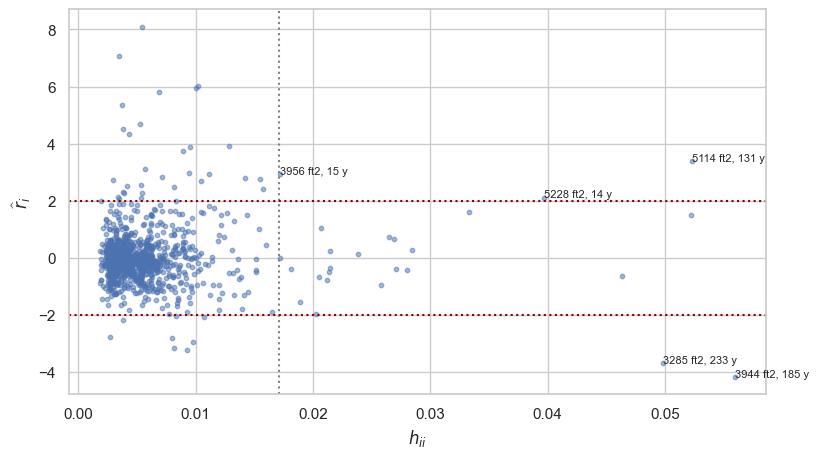

In [5]:
thr_h = 3 * ph / nh
big_h = hv[hv['h_ii'] > thr_h]
print(f'3(m+1)/n = {thr_h:.4f}: {len(big_h)} houses above, {np.sum(big_h["age"] > 100)} of them older than 100 years')
display(big_h.sort_values('h_ii', ascending=False)[['price', 'living_area', 'bathrooms', 'bedrooms', 'age', 'h_ii', 'r_i']].head(8))
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(hh, rh, s=10, alpha=0.5)
ax.axvline(thr_h, color='gray', ls=':')
for b in (-2, 2):
    ax.axhline(b, color='darkred', ls=':')
for k_ in hv.index[(hv['h_ii'] > thr_h) & (hv['r_i'].abs() > 2)]:
    ax.annotate(f'{hv.loc[k_, "living_area"]} ft2, {hv.loc[k_, "age"]} y', (hh[k_], rh[k_]), fontsize=8)
ax.set_xlabel('$h_{ii}$'); ax.set_ylabel('$\\widehat{r}_i$')
plt.show()

- 25 houses above $3(m+1)/n \approx 0.017$, 18 of them older than 100 years: as in HW04, leverage finds the implausible ages.
- High on both: a 3944 ft² house with one bathroom and 185 years (88 000 USD, $\widehat{r}_i \approx -4.2$), a 233-year-old 3285 ft² house for 59 000 USD, the two largest houses (5114 and 5228 ft²) and a 3956 ft² house of 15 years ($\widehat{r}_i \approx 2.9$). The points to check first, and to measure by DFBETAS and Cook's distance (Section 7).

**Step 3.** Residual plots.

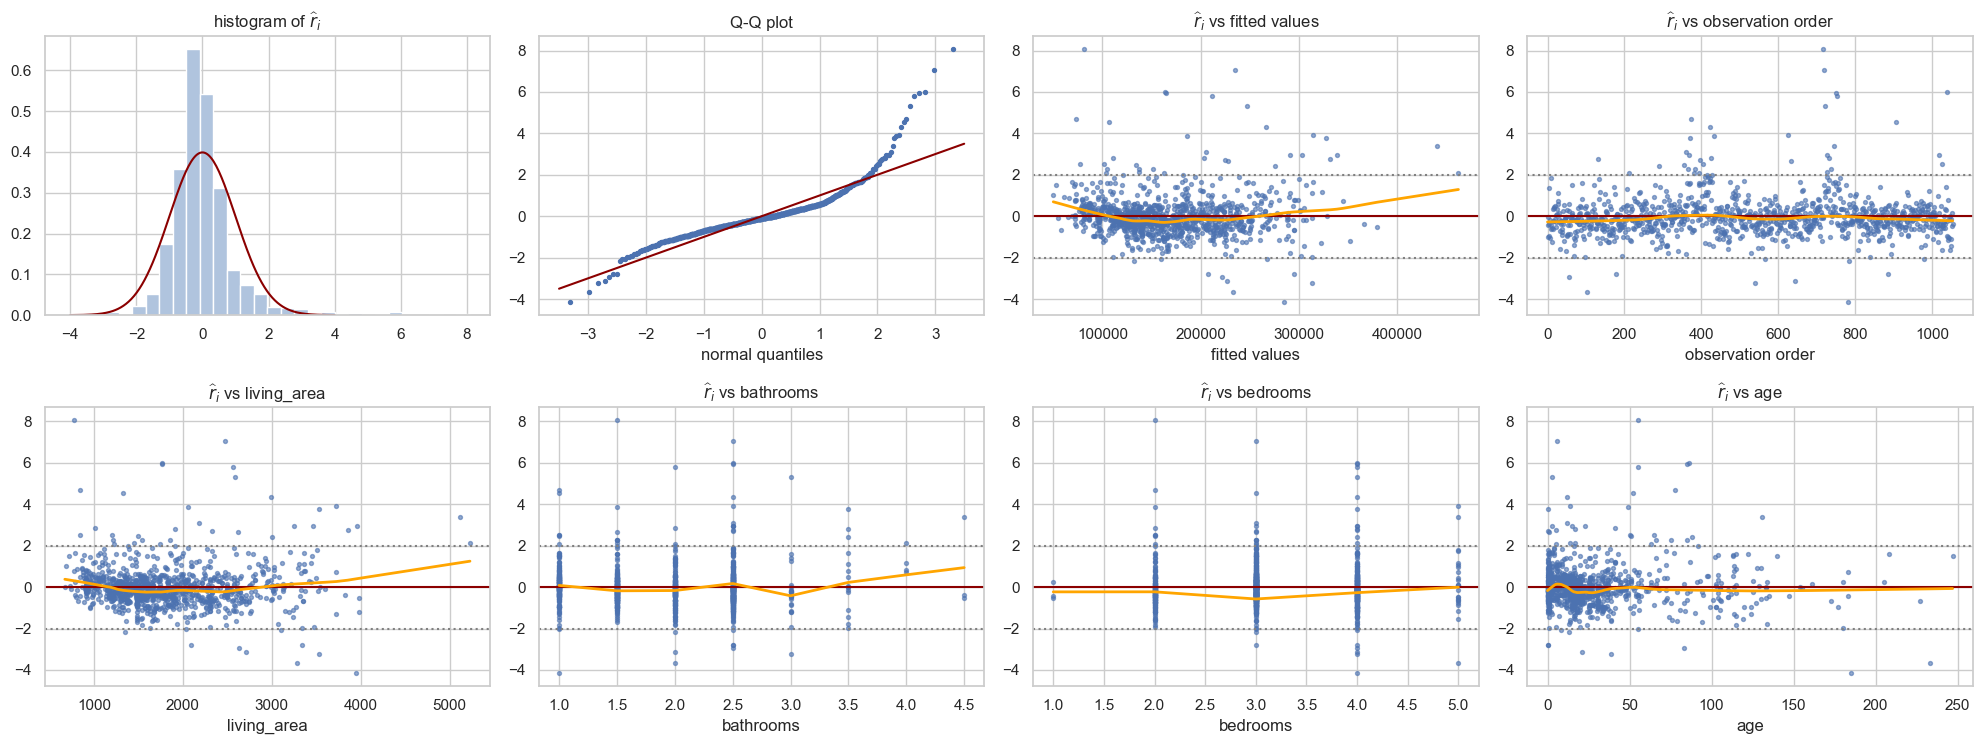

sd of r_i by quartile of the fitted values: [0.93, 0.68, 0.96, 1.3]


In [6]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)          # lowess on the discrete bathrooms / bedrooms
    residual_plots(fit_h, houses, ['living_area', 'bathrooms', 'bedrooms', 'age'])
print('sd of r_i by quartile of the fitted values:',
      hv.groupby(pd.qcut(fit_h.fittedvalues, 4), observed=True)['r_i'].std().round(2).tolist())

- A **funnel**: sd of $\widehat{r}_i$ by quartile of $\widehat{y}$ is 0.93, 0.68, 0.96, 1.30, largest for the most expensive predictions (the cheapest quartile also spreads more than the second). Key of Exercise 05, Section 5.4: $\widehat{\boldsymbol{\beta}}$ unbiased, but standard errors, tests and intervals are off; remedy $\ln(\text{price})$ or WLS (Exercise 09).
- The Q-Q plot bends up in the right tail (the expensive houses of Step 1): skewed to the right, the same direction as the funnel.
- Against `living_area` a mild upward curve at the large houses; against `age` the old houses spread out.

**Step 4.** Partial residuals for `age` and `living_area`, a broken line in age.

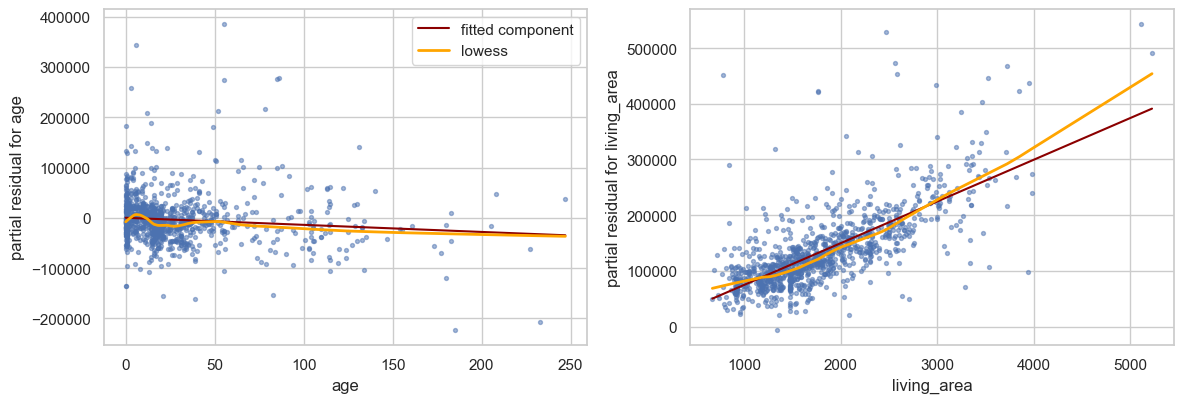

,R^2,s_n,coefficient of age,p of the extra age term
linear age,0.6032,48659.9731,-141.1062,NaN
broken line at 50,0.6044,48612.0991,61.8948,0.0802
broken line at 75,0.6065,48481.7386,97.3582,0.0032
broken line at 100,0.6061,48510.1931,8.3558,0.0063
broken line at 125,0.6053,48555.0985,-52.0433,0.0188
broken line at 150,0.6048,48585.9560,-76.8235,0.0407
age + age^2,0.6047,48595.3754,79.9812,0.0518


broken line at 100: slope 8.4 USD/year below 100, -517.6 above


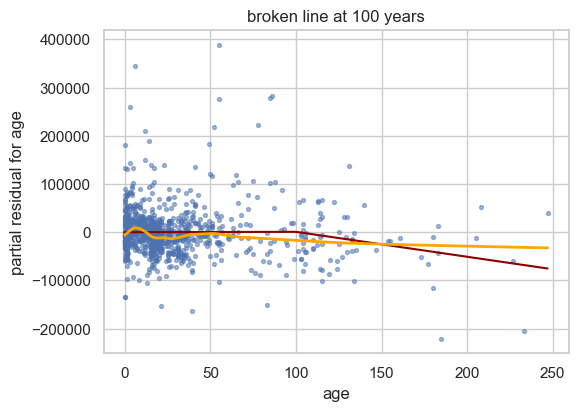

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
partial_residual_plot(fit_h, houses, 'age', axes[0])
partial_residual_plot(fit_h, houses, 'living_area', axes[1])
axes[0].legend()
plt.tight_layout()
plt.show()
rows_h = {'linear age': fit_h}
for c in [50, 75, 100, 125, 150]:
    rows_h[f'broken line at {c}'] = smf.ols(f'price ~ living_area + bathrooms + bedrooms + age + np.maximum(age - {c}, 0) + fireplace', data=houses).fit()
rows_h['age + age^2'] = smf.ols('price ~ living_area + bathrooms + bedrooms + age + I(age**2) + fireplace', data=houses).fit()
display(pd.DataFrame({k_: {'R^2': f.rsquared, 's_n': np.sqrt(f.scale),
                           'coefficient of age': f.params['age'],
                           'p of the extra age term': (f.pvalues.drop(['Intercept', 'fireplace[T.True]', 'living_area', 'bathrooms', 'bedrooms', 'age']).iloc[0]
                                                       if len(f.params) > 6 else np.nan)} for k_, f in rows_h.items()}).T)
fit_h100 = rows_h['broken line at 100']
print(f"broken line at 100: slope {fit_h100.params['age']:.1f} USD/year below 100, "
      f"{fit_h100.params['age'] + fit_h100.params['np.maximum(age - 100, 0)']:.1f} above")
fig, ax = plt.subplots(figsize=(6, 4.2))
partial_residual_plot(fit_h100, houses, 'age', ax, extra={'np.maximum(age - 100, 0)': lambda x: np.maximum(x - 100, 0)})
ax.set_title('broken line at 100 years')
plt.show()

- The PRP for `age` is flat up to roughly 75–100 years and falls after that; the straight line averages a flat part and a steep part.
- Broken line at 100 years: slope about 0 below 100, about $-520$ USD per year above ($p \approx 0.006$); breaks at 75–100 fit equally well, the square less clearly ($p \approx 0.05$).
- The break was chosen after looking at the plot and among five candidates: the $p$-values are optimistic (selective inference, Exercise 10).
- In `age + age^2` the "coefficient of age" is the slope at age 0, not comparable with the other rows.
- The gain is small ($R^2$ 0.603 → 0.606, $s_n$ 48 660 → 48 510): the old houses are few and doubtful (Step 2). Honest summary: "no age effect for ordinary houses, the old ones are cheaper and partly suspicious".
- `living_area`: a mild convex curve at the large houses, partly the funnel of Step 3; a log price would address both.

**Step 5.** AV plot for `bedrooms`.

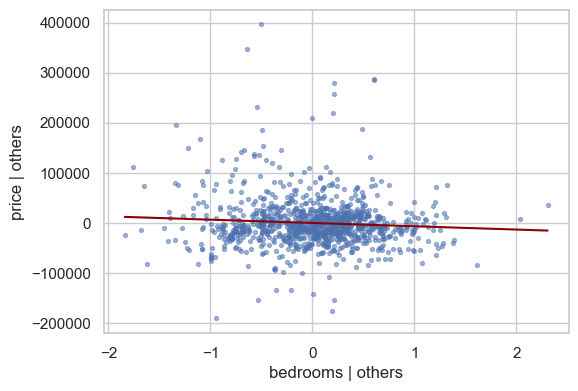

AV slope -6582.8 = beta_bedrooms -6582.8;  sd(bedrooms) = 0.740, sd(bedrooms | others) = 0.545


In [8]:
e_y, x_r = added_variable(fit_h, 'bedrooms')
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.scatter(x_r, e_y, s=8, alpha=0.5)
g = np.linspace(x_r.min(), x_r.max(), 2)
ax.plot(g, fit_h.params['bedrooms'] * g, color='darkred')
ax.set_xlabel('bedrooms | others'); ax.set_ylabel('price | others')
plt.show()
print(f'AV slope {x_r @ e_y / (x_r @ x_r):.1f} = beta_bedrooms {fit_h.params["bedrooms"]:.1f};'
      f'  sd(bedrooms) = {houses["bedrooms"].std(ddof=0):.3f}, sd(bedrooms | others) = {x_r.std():.3f}')

- Axes: price and bedrooms, both cleaned of living area, bathrooms, age and fireplace (FWL). Slope $\widehat{\beta}_{bedrooms} \approx -6583$: the bedroom paradox of HW04, Task 04.
- Horizontal spread 0.54 against 0.74 bedrooms ($R_j^2 \approx 0.46$): only about half of the variability of `bedrooms` is information about its own effect. "One more bedroom at the same area" happens in the data only within about ±1 bedroom.
- No single house carries the slope; the vertical funnel (expensive houses) is visible here too.

**Step 6.** Summary.
- The mean structure is roughly right, but the variance grows with the price and the residuals are skewed to the right: tests and intervals of the HW04 models are only approximate.
- A few houses are suspicious: 780 ft² for 474 000 USD, the duplicated 1764 ft² house, the old houses with large leverage.
- The age effect is not linear (flat, then falling after about 100 years) and rests on few doubtful houses.
- Next: check the suspicious records, measure how much the high-leverage houses move the fit (Section 7 today), try $\ln(\text{price})$ (Exercise 09).

## 4. PRESS residuals and the test of an outlier (pp. 119–127)

### 4.1 PRESS residuals
- Leave out the $i$-th observation, fit the model $M_{(-i)}$, predict $y_i$: $\widehat{y}_{(-i)} = \mathbf{x}_i^T\widehat{\boldsymbol{\beta}}_{(-i)}$.
- $i$-th **PRESS residual** (PRESS = prediction sum of squares): $\widehat{e}_{(-i)} = y_i - \widehat{y}_{(-i)}$.
- No refit is needed (Theorem 4.1 = Sherman–Morrison–Woodbury for $(\mathbf{X}_{(-i)}^T\mathbf{X}_{(-i)})^{-1}$):
  - Theorem 4.2: $\widehat{e}_{(-i)} = \dfrac{\widehat{e}_i}{1-h_{ii}}$,
  - Theorem 4.3: $\widehat{\boldsymbol{\beta}} - \widehat{\boldsymbol{\beta}}_{(-i)} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{x}_i\,\widehat{e}_{(-i)}$ and $\mathrm{SSE}_{(-i)} = \mathrm{SSE} - \dfrac{\widehat{e}_i^2}{1-h_{ii}}$,
  - Corollary 4.1: $\widehat{\sigma}^2_{(-i)} = \mathrm{SSE}_{(-i)}/(n-m-2)$ is unbiased.
- statsmodels `get_influence().resid_press`, R `rstandard(mod, type = "predictive")`.

Birth weight ($n = 24$), all $n$ refits against the formulas:

In [9]:
fit_b = smf.ols('Weight ~ Age + Sex', data=birth).fit()       # R: lm(Weight ~ Age + Sex)
Xb, yb = fit_b.model.exog, fit_b.model.endog
nb_, pb = Xb.shape                                             # pb = m + 1
XtX_inv_b = np.linalg.inv(Xb.T @ Xb)
hb = np.einsum('ij,jk,ik->i', Xb, XtX_inv_b, Xb)
eb = fit_b.resid.to_numpy()

press_loop, dbeta_loop, sse_loop = np.zeros(nb_), np.zeros((nb_, pb)), np.zeros(nb_)
for i in range(nb_):
    keep = np.arange(nb_) != i
    b_i = np.linalg.lstsq(Xb[keep], yb[keep], rcond=None)[0]     # model M_(-i)
    press_loop[i] = yb[i] - Xb[i] @ b_i
    dbeta_loop[i] = fit_b.params.to_numpy() - b_i
    sse_loop[i] = np.sum((yb[keep] - Xb[keep] @ b_i) ** 2)

press_b = eb / (1 - hb)                                                  # Theorem 4.2
dbeta_b = (XtX_inv_b @ Xb.T * press_b).T                                 # Theorem 4.3, 1)
sse_del_b = np.sum(eb ** 2) - eb ** 2 / (1 - hb)                         # Theorem 4.3, 2)
infl_b = fit_b.get_influence()
print(f'PRESS residuals: max |loop - e/(1-h)| = {np.abs(press_loop - press_b).max():.1e},'
      f'  max |statsmodels - e/(1-h)| = {np.abs(infl_b.resid_press - press_b).max():.1e}')
print(f'beta - beta_(-i): max |loop - formula| = {np.abs(dbeta_loop - dbeta_b).max():.1e};'
      f'  SSE_(-i): max |loop - formula| = {np.abs(sse_loop - sse_del_b).max():.1e}')
SST_b = np.sum((yb - yb.mean()) ** 2)
print(f'SSE = {np.sum(eb ** 2):.0f},  PRESS = sum of squared PRESS residuals = {np.sum(press_b ** 2):.0f} (statsmodels ess_press {infl_b.ess_press:.0f})')
print(f'R^2 = {fit_b.rsquared:.3f},  predicted R^2 = 1 - PRESS/SST = {1 - np.sum(press_b ** 2) / SST_b:.3f}')
pd.DataFrame({'Age': birth['Age'], 'Sex': birth['Sex'], 'h_ii': hb, 'e_i': eb, 'PRESS e_(-i)': press_b}).loc[np.argsort(-hb)[:4]]

PRESS residuals: max |loop - e/(1-h)| = 6.9e-12,  max |statsmodels - e/(1-h)| = 1.9e-12
beta - beta_(-i): max |loop - formula| = 2.0e-11;  SSE_(-i): max |loop - formula| = 3.0e-09
SSE = 658771,  PRESS = sum of squared PRESS residuals = 885495 (statsmodels ess_press 885495)
R^2 = 0.640,  predicted R^2 = 1 - PRESS/SST = 0.516


,Age,Sex,h_ii,e_i,PRESS e_(-i)
3,35,boy,0.2316,303.9811,395.6265
16,42,girl,0.2243,-94.2399,-121.4938
20,36,girl,0.1843,-166.8739,-204.5723
13,36,girl,0.1843,150.1261,184.0409


- Loop and formulas agree to rounding errors: $n$ refits replaced by one fit and the $h_{ii}$.
- $\mathrm{PRESS} = \sum_i \widehat{e}_{(-i)}^2 > \mathrm{SSE}$: SSE measures the fit, PRESS the prediction of points the model did not see. **Predicted $R^2$** $= 1 - \mathrm{PRESS}/\mathrm{SST}$ is the honest version of $R^2$; leave-one-out cross-validation for linear regression (Exercise 12).
- Remark 4.7, **fit/prediction dilemma**: the boy of week 35 has the largest $h_{ii} \approx 0.23$; his PRESS residual is $1/(1-0.23) \approx 1.3\times$ his residual. A point with a large $h_{ii}$ pulls the fit to itself; it looks well fitted, but is predicted badly.

### 4.2 Test of an outlier (Statement 4.1, Remarks 4.4–4.6)
- $\widehat{t}_i = \dfrac{\widehat{e}_i}{\widehat{\sigma}_{(-i)}\sqrt{1-h_{ii}}} \sim t(n-m-2)$ for $h_{ii} \ne 1$: **studentized PRESS residual** ($\widehat{e}_{(-i)}$ divided by its estimated standard deviation $\widehat{\sigma}_{(-i)}/\sqrt{1-h_{ii}}$, Remark 4.6).
- $H_0$: the $i$-th observation is not an outlier in $M$; reject if $|\widehat{t}_i| > t_{1-\alpha/2}(n-m-2)$.
- Equivalent: add a dummy variable $d_i = \mathbb{1}[\text{obs} = i]$ to the model (**mean-shift outlier model**); $\widehat{t}_i$ is the $t$-statistic of its coefficient.
- Testing **all** $n$ observations: about $\alpha n$ false alarms. **Bonferroni**: $|\widehat{t}_i| > t_{1-\alpha/(2n)}(n-m-2)$, then $P(\text{any false alarm}) \le \alpha$.

The 2004 cars, model of Exercise 07 ($n = 409$, $m + 1 = 11$):

In [10]:
form04 = 'consumption ~ Weight + HP + EngineSize + C(type, Treatment("Sedan")) + C(drive, Treatment("FWD"))'
fit04 = smf.ols(form04, data=d04).fit()          # R: lm(consumption ~ Weight + HP + EngineSize + type + drive)
infl04 = fit04.get_influence()
n4, p4 = fit04.model.exog.shape
t4 = infl04.resid_studentized_external
t_crit = stats.t.ppf(0.975, n4 - p4 - 1)
t_bonf = stats.t.ppf(1 - 0.05 / (2 * n4), n4 - p4 - 1)
print(f'|t_i| > t_0.975({n4 - p4 - 1}) = {t_crit:.2f}: {np.sum(np.abs(t4) > t_crit)} cars;'
      f'  > Bonferroni bound t_(1-0.05/(2n)) = {t_bonf:.2f}: {np.sum(np.abs(t4) > t_bonf)} cars')

# mean-shift model for the Hummer: the t statistic of its dummy is t_i
k_h = int(d04.index[d04['Name'] == 'Hummer H2'][0])
fit_shift = smf.ols(form04 + ' + hummer', data=d04.assign(hummer=(d04.index == k_h).astype(float))).fit()
print(f'Hummer: t_i = {t4[k_h]:.4f},  t of the dummy in the mean-shift model = {fit_shift.tvalues["hummer"]:.4f}')

ot = fit04.outlier_test()                      # R: car::outlierTest(mod)
ot.insert(0, 'Name', d04['Name'])
ot.sort_values('bonf(p)').head(5)

|t_i| > t_0.975(397) = 1.97: 19 cars;  > Bonferroni bound t_(1-0.05/(2n)) = 3.88: 2 cars


Hummer: t_i = 5.8008,  t of the dummy in the mean-shift model = 5.8008


,Name,student_resid,unadj_p,bonf(p)
161,Hummer H2,5.8008,1.3496e-08,5.5199e-06
209,Land Rover Discovery SE,4.0835,5.3675e-05,2.1953e-02
63,Chevrolet Astro,3.7225,2.2578e-04,9.2345e-02
388,Volkswagen Jetta GLS TDI 4dr,-3.4277,6.7240e-04,2.7501e-01
399,Volvo S40 4dr,1.2765,2.0254e-01,1.0000e+00


- 19 cars exceed 1.97, about the $0.05 \cdot 409 \approx 20$ false alarms expected even if the model were exactly right.
- With Bonferroni ($|\widehat{t}_i| > 3.88$): the **Hummer H2** ($\widehat{t}_i \approx 5.8$) and the **Land Rover Discovery** (4.1). `outlier_test` reports $p$-values multiplied by $n$ (`bonf(p)`, capped at 1).
- The Chevrolet Astro ($\widehat{t}_i \approx 3.7$) is not an outlier by this test; whether it **changes** the fit is a different question (Section 5).
- Remark 4.5: "outlier with respect to $M$". The Hummer is an outlier of this model: heavy off-road vehicles use more than weight and power predict. A missing variable, not necessarily a wrong record.

Does Bonferroni really keep the 5 %? Simulation with the same $\mathbf{X}$ and exactly normal errors:

In [11]:
rng = np.random.default_rng(8)
X4 = fit04.model.exog
M4 = np.eye(n4) - X4 @ np.linalg.solve(X4.T @ X4, X4.T)        # I - H; e_hat = (I - H) e does not depend on beta
h4 = 1 - np.diag(M4)
R = 2000
E = M4 @ rng.normal(size=(n4, R))                               # R simulated residual vectors, sigma = 1
SSE_sim = np.sum(E ** 2, axis=0)
r_sim = E / np.sqrt(SSE_sim / (n4 - p4) * (1 - h4)[:, None])
t_sim = r_sim * np.sqrt((n4 - p4 - 1) / (n4 - p4 - r_sim ** 2))
print(f'mean number of |t_i| > {t_crit:.2f} per data set: {np.mean(np.sum(np.abs(t_sim) > t_crit, axis=0)):.1f}')
print(f'P(at least one |t_i| > {t_crit:.2f}) = {np.mean(np.any(np.abs(t_sim) > t_crit, axis=0)):.3f}')
print(f'P(at least one |t_i| > {t_bonf:.2f}) = {np.mean(np.any(np.abs(t_sim) > t_bonf, axis=0)):.3f}   (Bonferroni, nominal <= 0.05)')
print(f'P(max |t_i| > 5.8, as large as the Hummer) = {np.mean(np.max(np.abs(t_sim), axis=0) > 5.8):.4f}')

mean number of |t_i| > 1.97 per data set: 20.5
P(at least one |t_i| > 1.97) = 1.000
P(at least one |t_i| > 3.88) = 0.043   (Bonferroni, nominal <= 0.05)
P(max |t_i| > 5.8, as large as the Hummer) = 0.0000


- Without correction about 20 "outliers" in every data set and at least one almost surely. With Bonferroni about 4 %: below 5 % as promised, and only slightly conservative, because the $\widehat{t}_i$ are nearly independent.
- A Hummer-sized $\widehat{t}_i$ practically never happens under the model.

## 5. Influence measures (pp. 128–132)
Which observation **changes** the fit? Measures built from $\widehat{\boldsymbol{\beta}} - \widehat{\boldsymbol{\beta}}_{(-i)} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{x}_i\,\widehat{e}_i/(1-h_{ii})$: they combine a large residual and a large $h_{ii}$.

| measure | formula | effect of deleting $i$ on | rule of thumb (p. 132) | statsmodels / R |
|---|---|---|---|---|
| **DFBETAS** | $\dfrac{\widehat{\beta}_j - \widehat{\beta}_{(-i)j}}{\widehat{\sigma}_{(-i)}\sqrt{v_j}}$, $v_j = [(\mathbf{X}^T\mathbf{X})^{-1}]_{jj}$ | one coefficient $\widehat{\beta}_j$, in units of its SE | $\lvert\mathrm{DFBETAS}_{j,i}\rvert > 1$ (p. 129 also $2/\sqrt{n}$) | `dfbetas` / `dfbetas()` |
| **Cook's distance** | $D_i = \dfrac{\widehat{r}_i^2}{m+1}\,\dfrac{h_{ii}}{1-h_{ii}}$ | the whole $\widehat{\boldsymbol{\beta}}$, equivalently all $\widehat{\mathbf{y}}$ | $D_i > F_{1/2}(m+1, n-m-1)$ | `cooks_distance[0]` / `cooks.distance()` |
| **DFFITS** | $\dfrac{\widehat{y}_i - \widehat{y}_{(-i)}}{\widehat{\sigma}_{(-i)}\sqrt{h_{ii}}} = \widehat{t}_i\sqrt{\dfrac{h_{ii}}{1-h_{ii}}}$ | its own fitted value $\widehat{y}_i$ | $\lvert\mathrm{DFFITS}_i\rvert > 3\sqrt{\dfrac{m+1}{n-m-1}}$ | `dffits[0]` / `dffits()` |
| leverage | $h_{ii}$ | | $h_{ii} > 3(m+1)/n$ | `hat_matrix_diag` / `hatvalues()` |

- All of them in one table: statsmodels `get_influence().summary_frame()`, R `influence.measures(mod)` (Remark 4.10). R also reports **COVRATIO** (change of $\det\mathsf{Cov}\,\widehat{\boldsymbol{\beta}}$ without the $i$-th point), not in the lecture.
- DFBETAS and DFFITS use $\widehat{\sigma}_{(-i)}$ (and $\widehat{t}_i$), Cook's distance uses $s_n$ (and $\widehat{r}_i$).

### 5.1 By hand on the birth weight
The refits of Section 4.1 against the formulas and against statsmodels:

In [12]:
sigma_del_b = np.sqrt(sse_del_b / (nb_ - pb - 1))
v_b = np.diag(XtX_inv_b)
r_b = infl_b.resid_studentized_internal
t_b = infl_b.resid_studentized_external
dfbetas_b = dbeta_loop / (sigma_del_b[:, None] * np.sqrt(v_b))          # definition, from the n refits
cook_b = r_b ** 2 / pb * hb / (1 - hb)                                    # computational form, p. 130
dffits_b = t_b * np.sqrt(hb / (1 - hb))
yhat_del = np.array([Xb @ (fit_b.params.to_numpy() - dbeta_loop[i]) for i in range(nb_)])     # y_hat_(-i), all n points
cook_yhat = np.sum((fit_b.fittedvalues.to_numpy() - yhat_del) ** 2, axis=1) / (pb * fit_b.scale)   # Remark 4.9
print(f'DFBETAS: max |definition - statsmodels| = {np.abs(dfbetas_b - infl_b.dfbetas).max():.1e}')
print(f'Cook   : max |formula - statsmodels| = {np.abs(cook_b - infl_b.cooks_distance[0]).max():.1e},'
      f'  max |formula - sum (y_hat - y_hat_(-i))^2 / ((m+1) s_n^2)| = {np.abs(cook_b - cook_yhat).max():.1e}')
print(f'DFFITS : max |formula - statsmodels| = {np.abs(dffits_b - infl_b.dffits[0]).max():.1e}')
print(f'thresholds: 2/sqrt(n) = {2 / np.sqrt(nb_):.3f};  F_1/2({pb}, {nb_ - pb}) = {stats.f.ppf(0.5, pb, nb_ - pb):.3f};'
      f'  DFFITS 3 sqrt((m+1)/(n-m-1)) = {3 * np.sqrt(pb / (nb_ - pb)):.3f};  3(m+1)/n = {3 * pb / nb_:.3f}')
sf_b = infl_b.summary_frame()                                             # R: influence.measures(mod)
sf_b.insert(0, 'Age', birth['Age']); sf_b.insert(1, 'Sex', birth['Sex'])
sf_b.sort_values('cooks_d', ascending=False).head(4)

DFBETAS: max |definition - statsmodels| = 1.9e-14
Cook   : max |formula - statsmodels| = 6.0e-15,  max |formula - sum (y_hat - y_hat_(-i))^2 / ((m+1) s_n^2)| = 3.4e-14
DFFITS : max |formula - statsmodels| = 1.8e-14
thresholds: 2/sqrt(n) = 0.408;  F_1/2(3, 21) = 0.815;  DFFITS 3 sqrt((m+1)/(n-m-1)) = 1.134;  3(m+1)/n = 0.375


,Age,Sex,dfb_Intercept,dfb_Sex[T.girl],dfb_Age,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
3,35,boy,0.9718,-0.3800,-0.9285,0.3853,1.9580,0.2316,1.0751,2.1134,1.1604
0,40,boy,0.2972,0.3861,-0.3300,0.1096,-1.5501,0.1204,-0.5735,-1.6075,-0.5948
7,40,boy,-0.2843,-0.3693,0.3157,0.1013,1.4900,0.1204,0.5513,1.5377,0.5689
12,40,girl,-0.2391,0.3083,0.2397,0.0894,1.5185,0.1042,0.5179,1.5706,0.5356


In [13]:
fit_b35 = smf.ols('Weight ~ Age + Sex', data=birth.drop(index=3)).fit()        # without the boy of week 35
comp_b = pd.DataFrame({'all 24': fit_b.params, 'without the boy of week 35': fit_b35.params, 'SE (all 24)': fit_b.bse})
comp_b['change in SE'] = (comp_b['all 24'] - comp_b['without the boy of week 35']) / comp_b['SE (all 24)']
comp_b['DFBETAS'] = infl_b.dfbetas[3]
display(comp_b)
print(f"p-value of Sex: {fit_b.pvalues['Sex[T.girl]']:.3f} with him, {fit_b35.pvalues['Sex[T.girl]']:.3f} without him")

,all 24,without the boy of week 35,SE (all 24),change in SE,DFBETAS
Intercept,-1610.2825,-2318.0315,786.0777,0.9004,0.9718
Sex[T.girl],-163.0393,-137.4050,72.8082,-0.3521,-0.3800
Age,120.8943,138.4973,20.4630,-0.8602,-0.9285


p-value of Sex: 0.036 with him, 0.059 without him


- The boy of week 35: Cook's $D \approx 0.39$ (the largest, but below $F_{1/2}(3, 21) \approx 0.81$), $|\mathrm{DFFITS}| \approx 1.16$ (just above 1.13), $\mathrm{DFBETAS}$ of the intercept and of `Age` about $\pm 0.95$.
- Without him the slope in age grows from 121 to 139 g/week, the sex difference shrinks from $-163$ to $-137$ g and its $p$-value crosses 0.05 (Exercise 06, Section 4.3).
- "Change in SE" uses the SE of the full fit, DFBETAS the $\widehat{\sigma}_{(-i)}$: nearly the same numbers.
- One newborn of 24 decides whether "girls are lighter" is significant: report both fits, not just one.

### 5.2 Cook's distance as a confidence ellipsoid (Remark 4.8)
- $100(1-\alpha)\,\%$ confidence region for $\boldsymbol{\beta}$ (Exercise 06, Section 5): $C(\alpha) = \{\boldsymbol{\beta}: (\widehat{\boldsymbol{\beta}} - \boldsymbol{\beta})^T\mathbf{X}^T\mathbf{X}(\widehat{\boldsymbol{\beta}} - \boldsymbol{\beta}) \le (m+1)s_n^2 F_{1-\alpha}(m+1, n-m-1)\}$.
- $D_i$ is the same quadratic form for $\boldsymbol{\beta} = \widehat{\boldsymbol{\beta}}_{(-i)}$: $\ \widehat{\boldsymbol{\beta}}_{(-i)} \in C(\alpha) \iff D_i \le F_{1-\alpha}(m+1, n-m-1)$.
- Rule $D_i > F_{1/2}$: deleting one point moves $\widehat{\boldsymbol{\beta}}$ outside the 50 % confidence ellipsoid. Values of $F_{1/2}$:

In [14]:
print(pd.DataFrame({f'm+1 = {k}': {f'n-m-1 = {d}': stats.f.ppf(0.5, k, d) for d in (10, 20, 50, 400)} for k in (1, 2, 3, 6, 11)}).round(3))

             m+1 = 1  m+1 = 2  m+1 = 3  m+1 = 6  m+1 = 11
n-m-1 = 10     0.490    0.743    0.845    0.954     1.006
n-m-1 = 20     0.472    0.718    0.816    0.922     0.972
n-m-1 = 50     0.462    0.703    0.800    0.903     0.953
n-m-1 = 400    0.456    0.694    0.790    0.893     0.942


- $F_{1/2}$ is the median of $F$: between about 0.45 ($m+1 = 1$) and 0.95; close to 1 only with many parameters and large $n$. The rule $D_i > 1$ is slightly more lenient.
- A picture needs two parameters: simple regression, shown on the stars in Section 6.

### 5.3 The 2004 cars

In [15]:
def influence_table(fit, labels):
    """h_ii, t_i, Cook, DFFITS, the largest |DFBETAS| and the rules of p. 132 (Remark 4.10)."""
    inf = fit.get_influence()
    n_, p_ = fit.model.exog.shape
    dfb = pd.DataFrame(inf.dfbetas, columns=fit.model.exog_names)
    tab = pd.DataFrame({'label': labels, 'h_ii': inf.hat_matrix_diag, 't_i': inf.resid_studentized_external,
                        'cook': inf.cooks_distance[0], 'dffits': inf.dffits[0],
                        'max|dfbetas|': dfb.abs().max(axis=1), 'for': dfb.abs().idxmax(axis=1)})
    tab['flag_h'] = tab['h_ii'] > 3 * p_ / n_
    tab['flag_cook'] = tab['cook'] > stats.f.ppf(0.5, p_, n_ - p_)
    tab['flag_dffits'] = tab['dffits'].abs() > 3 * np.sqrt(p_ / (n_ - p_))
    tab['flag_dfbetas'] = tab['max|dfbetas|'] > 1
    return tab


tab04 = influence_table(fit04, d04['Name'])
print(f'n = {n4}, m+1 = {p4}: F_1/2 = {stats.f.ppf(0.5, p4, n4 - p4):.3f}, DFFITS bound {3 * np.sqrt(p4 / (n4 - p4)):.3f}, 3(m+1)/n = {3 * p4 / n4:.3f}')
print('flagged cars per rule:', tab04.filter(like='flag').sum().to_dict())
print(f'any |DFBETAS| > 2/sqrt(n) = {2 / np.sqrt(n4):.3f}: {np.sum(tab04["max|dfbetas|"] > 2 / np.sqrt(n4))} cars')
tab04.sort_values('cook', ascending=False).head(6)

n = 409, m+1 = 11: F_1/2 = 0.942, DFFITS bound 0.499, 3(m+1)/n = 0.081
flagged cars per rule: {'flag_h': 1, 'flag_cook': 0, 'flag_dffits': 8, 'flag_dfbetas': 1}
any |DFBETAS| > 2/sqrt(n) = 0.099: 119 cars


,label,h_ii,t_i,cook,dffits,max|dfbetas|,for,flag_h,flag_cook,flag_dffits,flag_dfbetas
161,Hummer H2,0.0583,5.8008,0.1750,1.4431,1.0566,Intercept,False,False,True,True
63,Chevrolet Astro,0.0729,3.7225,0.0960,1.0441,0.6846,"C(type, Treatment(""Sedan""))[T.Minivan]",False,False,True,False
382,Toyota Tundra Access Cab V6 SR5,0.0553,2.9471,0.0454,0.7132,0.4765,"C(type, Treatment(""Sedan""))[T.Pickup]",False,False,True,False
209,Land Rover Discovery SE,0.0279,4.0835,0.0418,0.6912,0.3341,EngineSize,False,False,True,False
233,Mazda B4000 SE Cab Plus,0.0656,2.4812,0.0388,0.6572,0.4948,"C(type, Treatment(""Sedan""))[T.Pickup]",False,False,True,False
22,Audi S4 Quattro 4dr,0.0363,2.8305,0.0270,0.5496,0.3013,HP,False,False,True,False


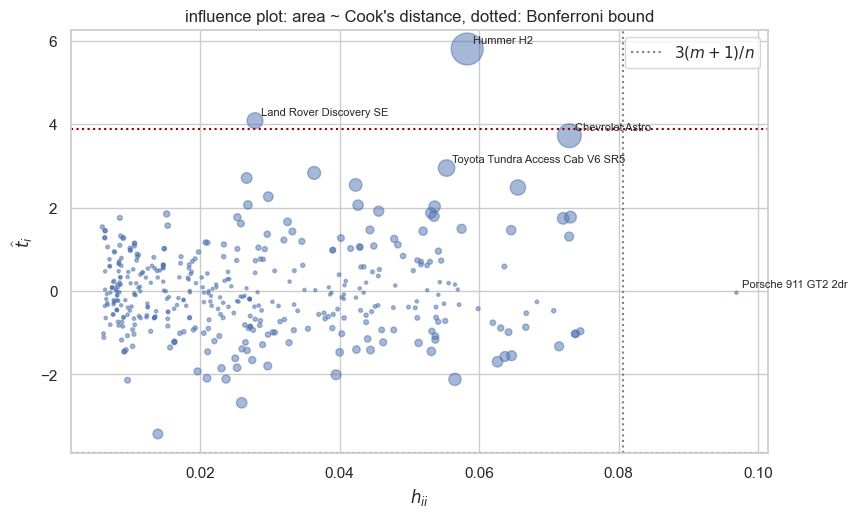

Hummer removed, change of the coefficients in units of SE: {'Intercept': -1.02, 'Weight': 0.9, 'HP': -0.52, 'EngineSize': -0.02}
Weight per 1000 lb: 1.421 with the Hummer, 1.301 without


In [16]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(tab04['h_ii'], tab04['t_i'], s=3000 * tab04['cook'] + 5, alpha=0.5)
ax.axvline(3 * p4 / n4, color='gray', ls=':', label='$3(m+1)/n$')
for b in (-t_bonf, t_bonf):
    ax.axhline(b, color='darkred', ls=':')
for k_ in tab04['cook'].nlargest(4).index.tolist() + [int(tab04['h_ii'].idxmax())]:
    ax.annotate(tab04.loc[k_, 'label'], (tab04.loc[k_, 'h_ii'], tab04.loc[k_, 't_i']), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('$h_{ii}$'); ax.set_ylabel('$\\widehat{t}_i$'); ax.legend()
ax.set_title("influence plot: area ~ Cook's distance, dotted: Bonferroni bound")
plt.show()
# the same with statsmodels: sm.graphics.influence_plot(fit04, criterion='cooks')

fit04_wo = smf.ols(form04, data=d04.drop(index=k_h)).fit()
shift = ((fit04.params - fit04_wo.params) / fit04.bse)[['Intercept', 'Weight', 'HP', 'EngineSize']]
print('Hummer removed, change of the coefficients in units of SE:', shift.round(2).to_dict())
print(f"Weight per 1000 lb: {1000 * fit04.params['Weight']:.3f} with the Hummer, {1000 * fit04_wo.params['Weight']:.3f} without")

- **Hummer H2**: Cook's $D \approx 0.18$, far below $F_{1/2} \approx 0.94$; but $\mathrm{DFFITS} \approx 1.4$ (bound 0.50) and $\mathrm{DFBETAS}$ about 0.94 for `Weight`, 1.06 for the intercept. Deleting it lowers the weight effect by almost one standard error.
- **Chevrolet Astro**: $\mathrm{DFFITS} \approx 1.0$, $\mathrm{DFBETAS}$ about 0.7 for the minivan dummy: among few minivans, it pulls their level.
- **Porsche 911 GT2**: the largest $h_{ii}$, Cook's $D \approx 0$. Large leverage, no influence: it lies on the plane (Exercise 07, Section 4).
- With 11 parameters Cook's distance spreads the change over all coefficients, and fires for no car; DFFITS fires for 8 cars, $|\mathrm{DFBETAS}| > 1$ only for the Hummer, $2/\sqrt{n}$ for 119 of 409 cars. **The rules only sort the points to look at**, they are not tests.

### 5.4 What to do with an influential point
1. Check the record (typo, units, duplicate, a different population such as hybrids).
2. Report the fit with and without it; if a conclusion depends on one point, say so.
3. Improve the model (missing variable: off-road vehicles; transformation: Exercise 09).
4. Use a method that limits the influence of any single point: robust regression (Section 6).
- Do not delete points only because a rule flagged them; the next fit will flag new ones.

## 6. Masking and robust regression

### 6.1 The stars of CYG OB1
Hertzsprung–Russell diagram of 47 stars: log surface temperature against log light intensity (Rousseeuw & Leroy, R `robustbase::starsCYG`).

OLS all stars: slope -0.413 (p = 0.16);  without the 4 stars with log_Te < 3.6: slope 2.047


F_1/2 = 0.704, DFFITS bound 0.632, Bonferroni bound for t_i 3.50, 3(m+1)/n = 0.128


,label,h_ii,t_i,cook,dffits,max|dfbetas|,for,flag_h,flag_cook,flag_dffits,flag_dfbetas
29,30,0.1983,1.3885,0.2337,0.6907,0.6662,Intercept,True,False,True,False
19,20,0.1941,1.0649,0.1362,0.5226,0.5036,Intercept,True,False,False,False
10,11,0.1941,0.7439,0.0673,0.3651,0.3518,Intercept,True,False,False,False
33,34,0.1941,1.9058,0.4132,0.9353,0.9012,Intercept,True,False,True,False
6,7,0.0781,-1.0269,0.0446,-0.2988,0.2647,Intercept,False,False,False,False
35,36,0.0460,1.3465,0.0429,0.2956,0.2167,log_Te,False,False,False,False


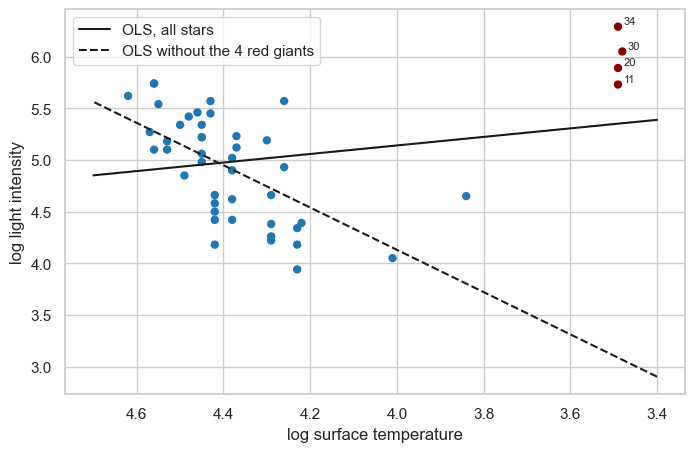

In [17]:
fit_s = smf.ols('log_light ~ log_Te', data=stars).fit()          # R: lm(log.light ~ log.Te)
giants = stars['log_Te'] < 3.6
fit_s_main = smf.ols('log_light ~ log_Te', data=stars[~giants]).fit()
print(f'OLS all stars: slope {fit_s.params["log_Te"]:.3f} (p = {fit_s.pvalues["log_Te"]:.2f});'
      f'  without the {giants.sum()} stars with log_Te < 3.6: slope {fit_s_main.params["log_Te"]:.3f}')
tab_s = influence_table(fit_s, stars['star'])
print(f'F_1/2 = {stats.f.ppf(0.5, 2, 45):.3f}, DFFITS bound {3 * np.sqrt(2 / 45):.3f}, Bonferroni bound for t_i {stats.t.ppf(1 - 0.05 / 94, 44):.2f}, 3(m+1)/n = {6 / 47:.3f}')
display(tab_s.sort_values('h_ii', ascending=False).head(6))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(stars['log_Te'], stars['log_light'], c=np.where(giants, 'darkred', 'tab:blue'), s=25)
for k_ in stars.index[giants]:
    ax.annotate(stars.loc[k_, 'star'], (stars.loc[k_, 'log_Te'], stars.loc[k_, 'log_light']), fontsize=8, xytext=(4, 2), textcoords='offset points')
g_s = np.linspace(3.4, 4.7, 2)
ax.plot(g_s, fit_s.params['Intercept'] + fit_s.params['log_Te'] * g_s, color='k', label='OLS, all stars')
ax.plot(g_s, fit_s_main.params['Intercept'] + fit_s_main.params['log_Te'] * g_s, color='k', ls='--', label='OLS without the 4 red giants')
ax.set_xlabel('log surface temperature'); ax.set_ylabel('log light intensity'); ax.legend()
ax.invert_xaxis()                                   # astronomers draw temperature decreasing to the right
plt.show()

- The cloud is the **main sequence** (light grows with temperature); the 4 stars on the right (low temperature; 11, 20, 30, 34) are **red giants**, a different population.
- OLS on all stars: a slightly **negative** slope, $R^2 \approx 0.04$: the giants turn the line. Without them the slope is about $+2$.
- Yet single-case diagnostics barely see them: no $|\widehat{t}_i|$ near the Bonferroni bound, every Cook's $D$ below $F_{1/2}$, all $h_{ii} \approx 0.19$ (above $3(m+1)/n$, but only "high leverage"). Only DFFITS of stars 30 and 34 slightly exceeds the bound.
- **Masking**: deleting one giant changes little, because the other three hold the line. Single-case deletion cannot find a group of outliers.

Cook's distance in the plane of the two parameters: the $\widehat{\boldsymbol{\beta}}_{(-i)}$ of all 47 stars (Theorem 4.3) and the confidence ellipses $C(\alpha)$.

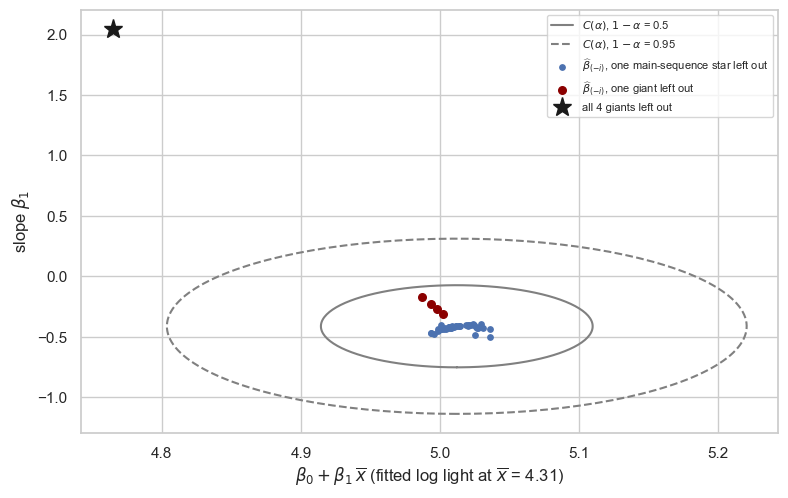

Cook distance of the 4 giants left out together: 41.4


In [18]:
Xs, ys = fit_s.model.exog, fit_s.model.endog
XtX_s = Xs.T @ Xs
h_s = fit_s.get_influence().hat_matrix_diag
beta_del_s = fit_s.params.to_numpy() - (np.linalg.solve(XtX_s, Xs.T) * (fit_s.resid.to_numpy() / (1 - h_s))).T


def ellipse(center, A, c, k=200):
    """Points b with (b - center)^T A (b - center) = c."""
    w, V = np.linalg.eigh(A)
    u = np.linspace(0, 2 * np.pi, k)
    return center + (V @ (np.sqrt(c / w)[:, None] * np.vstack([np.cos(u), np.sin(u)]))).T


# (beta_0, beta_1) are strongly correlated (x_bar = 4.3 is far from 0) and the ellipse is a thin line;
# draw it in theta = A beta = (beta_0 + beta_1 x_bar, beta_1), the level at x_bar and the slope.
# The quadratic form, hence D_i and C(alpha), does not depend on the parametrization.
x_bar = stars['log_Te'].mean()
A = np.array([[1.0, x_bar], [0.0, 1.0]])
A_inv = np.linalg.inv(A)
fig, ax = plt.subplots(figsize=(9, 5.5))
for lev, ls in [(0.5, '-'), (0.95, '--')]:
    el = ellipse(A @ fit_s.params.to_numpy(), A_inv.T @ XtX_s @ A_inv, 2 * fit_s.scale * stats.f.ppf(lev, 2, 45))
    ax.plot(el[:, 0], el[:, 1], color='gray', ls=ls, label=f'$C(\\alpha)$, $1-\\alpha$ = {lev}')
th_del = beta_del_s @ A.T
ax.scatter(th_del[~giants, 0], th_del[~giants, 1], s=15, label='$\\widehat{\\beta}_{(-i)}$, one main-sequence star left out')
ax.scatter(th_del[giants, 0], th_del[giants, 1], s=30, color='darkred', label='$\\widehat{\\beta}_{(-i)}$, one giant left out')
ax.plot(*(A @ fit_s_main.params.to_numpy()), 'k*', ms=14, label='all 4 giants left out')
ax.set_xlabel(f'$\\beta_0 + \\beta_1\\,\\overline{{x}}$ (fitted log light at $\\overline{{x}}$ = {x_bar:.2f})'); ax.set_ylabel('slope $\\beta_1$')
ax.legend(fontsize=8)
plt.show()
print(f'Cook distance of the 4 giants left out together: '
      f'{(fit_s.params - fit_s_main.params).to_numpy() @ XtX_s @ (fit_s.params - fit_s_main.params).to_numpy() / (2 * fit_s.scale):.1f}')

- Every single deletion stays inside the 50 % ellipse ($D_i < F_{1/2}$); the four giants deleted together land far outside even the 95 % ellipse (the same quadratic form gives about 41).
- In $(\beta_0, \beta_1)$ the ellipse would be a thin line ($\overline{x} \approx 4.3$ is far from 0, the estimates are strongly correlated); the plot uses the level at $\overline{x}$ and the slope, whose estimates are uncorrelated: the same ellipse with axes parallel to the coordinates.
- Generalizations for groups exist, but which group to try? Robust regression answers differently: fit the majority, then look at who does not fit.

### 6.2 M-estimators
OLS minimizes $\sum_i \widehat{e}_i^2$: one large residual dominates. An **M-estimator** minimizes $\sum_i \rho(\widehat{e}_i/s)$ with a $\rho$ that grows slower than the square:
- $\psi = \rho'$, estimating equations $\sum_i \psi(\widehat{e}_i/s)\,\mathbf{x}_i = \mathbf{0}$ (OLS: $\psi(u) = u$, the normal equations),
- weights $w_i = \psi(u_i)/u_i$, $u_i = \widehat{e}_i/s$: the equations are those of **weighted least squares** with weights $w_i$,
- $s$: a robust scale, $\mathrm{MAD} = \mathrm{median}|\widehat{e}_i|/0.6745$ (consistent for $\sigma$ under normality).

| | $\rho(u)$ | weight $w(u)$ | constant (95 % efficiency under normality) |
|---|---|---|---|
| **Huber** | $u^2/2$ for $\lvert u\rvert \le k$, $k\lvert u\rvert - k^2/2$ otherwise | $\min(1, k/\lvert u\rvert)$ | $k = 1.345$ |
| **Tukey bisquare** (biweight) | bounded: $\frac{c^2}{6}\left[1 - (1-(u/c)^2)^3\right]$ for $\lvert u\rvert \le c$, $c^2/6$ otherwise | $(1-(u/c)^2)^2$ for $\lvert u\rvert \le c$, 0 otherwise | $c = 4.685$ |

**IRLS** (iteratively reweighted least squares): start from OLS, compute $s$ and $w_i$, refit WLS, repeat until $\widehat{\boldsymbol{\beta}}$ stops changing. statsmodels `sm.RLM` / `smf.rlm`, R `MASS::rlm`.

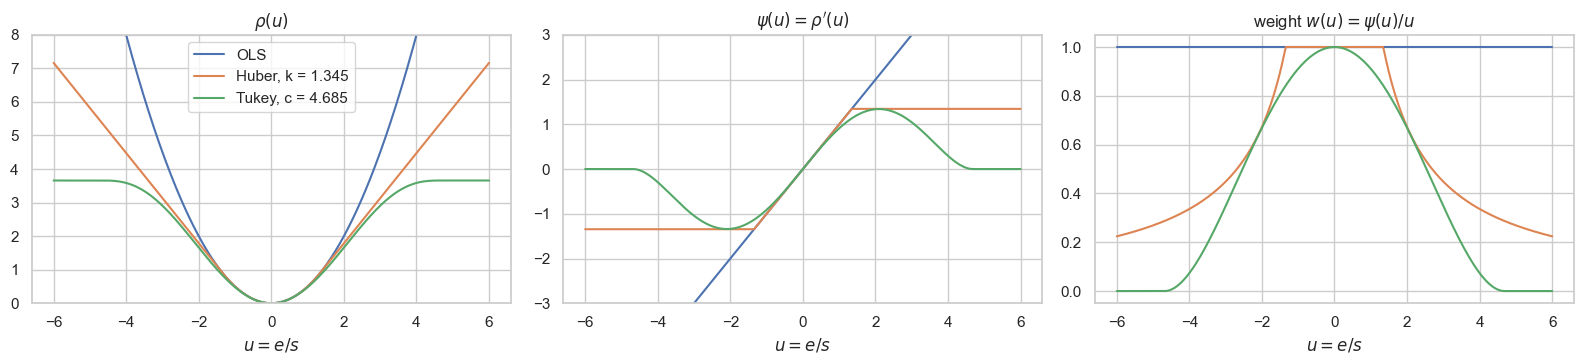

Huber by IRLS (11 steps): [ 6.8659 -0.4285];  statsmodels RLM: [ 6.8659 -0.4285]
Tukey started from OLS, statsmodels RLM: [ 6.8235 -0.418 ]
weights of the giants: Huber [1. 1. 1. 1.] , Tukey [0.98 0.95 0.92 0.85]


In [19]:
u = np.linspace(-6, 6, 400)
norms_ = {'OLS': None, 'Huber, k = 1.345': sm.robust.norms.HuberT(t=1.345), 'Tukey, c = 4.685': sm.robust.norms.TukeyBiweight(c=4.685)}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for lab, nrm in norms_.items():
    axes[0].plot(u, u ** 2 / 2 if nrm is None else nrm.rho(u), label=lab)
    axes[1].plot(u, u if nrm is None else nrm.psi(u), label=lab)
    axes[2].plot(u, np.ones_like(u) if nrm is None else nrm.weights(u), label=lab)
for ax, tt in zip(axes, ['$\\rho(u)$', '$\\psi(u) = \\rho\'(u)$', 'weight $w(u) = \\psi(u)/u$']):
    ax.set_title(tt); ax.set_xlabel('$u = e/s$')
axes[0].set_ylim(0, 8); axes[1].set_ylim(-3, 3); axes[0].legend()
plt.tight_layout()
plt.show()


def irls(X, y, norm, beta0, maxiter=100, tol=1e-10):
    """M-estimator by IRLS; scale = MAD of the residuals (around 0, as statsmodels RLM), updated in every step."""
    b = beta0.copy()
    s = np.median(np.abs(y - X @ b)) / 0.6745
    for it in range(maxiter):
        w = norm.weights((y - X @ b) / s)
        b_new = np.linalg.lstsq(X * np.sqrt(w)[:, None], y * np.sqrt(w), rcond=None)[0]     # WLS step
        s = np.median(np.abs(y - X @ b_new)) / 0.6745
        if np.max(np.abs(b_new - b)) < tol:
            return b_new, w, s, it + 1
        b = b_new
    return b, w, s, maxiter


b_hub, w_hub, s_hub, it_hub = irls(Xs, ys, sm.robust.norms.HuberT(), fit_s.params.to_numpy())
rlm_hub = sm.RLM(ys, Xs, M=sm.robust.norms.HuberT()).fit()          # R: MASS::rlm(log.light ~ log.Te)
rlm_tuk = sm.RLM(ys, Xs, M=sm.robust.norms.TukeyBiweight()).fit()   # R: MASS::rlm(..., psi = psi.bisquare)
print(f'Huber by IRLS ({it_hub} steps): {b_hub};  statsmodels RLM: {rlm_hub.params}')
print(f'Tukey started from OLS, statsmodels RLM: {rlm_tuk.params}')
print('weights of the giants: Huber', rlm_hub.weights[giants.to_numpy()].round(2), ', Tukey', rlm_tuk.weights[giants.to_numpy()].round(2))

- The hand-written IRLS reproduces `RLM`.
- **Both M-estimators keep the negative slope.** The giants have small residuals with respect to the OLS line they pulled (large $h_{ii}$ again): their weights stay near 1.
- M-estimators limit the influence of a large **residual**, not of a large **leverage**. Against bad leverage points they are no better than OLS (breakdown point $1/n$: one point placed far enough in $\mathbf{x}$ can move the fit arbitrarily).

### 6.3 LTS and a robust start
**Least trimmed squares** (LTS): minimize the sum of the $h$ smallest squared residuals, $\sum_{i=1}^{h} \widehat{e}^2_{(i)}$, with $h = \lfloor (n + m + 2)/2 \rfloor$: the best fitting half of the data.
- Breakdown point about 50 %: the estimate stays bounded as long as fewer than about half of the data are arbitrary.
- No formula: random starts from $m+1$ points, then **C-steps** (fit the $h$ points with the smallest residuals, recompute the residuals, repeat; each step does not increase the criterion).
- R `robustbase::ltsReg`; in Python a few lines. Then use LTS as the start of Tukey's M-estimator with a fixed robust scale: the idea of the **MM-estimator** (R `robustbase::lmrob`, `MASS::rlm(..., method = "MM")`), robust and efficient.

,Intercept,log_Te
"OLS, all",6.7935,-0.4133
OLS without giants,-4.0565,2.0467
Huber,6.8659,-0.4285
Tukey from OLS,6.8235,-0.4180
LTS,-13.6240,4.2192
Tukey from LTS,-5.0818,2.2786


Tukey from LTS, stars with weight < 0.1: [11, 20, 30, 34]


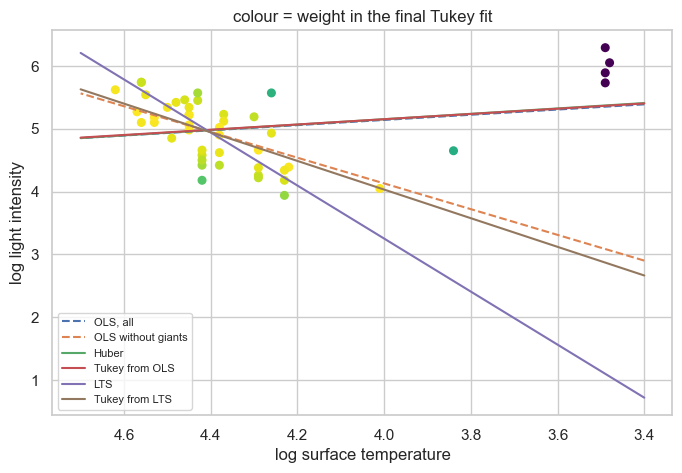

In [20]:
def lts(X, y, h=None, n_starts=1000, seed=1):
    """Least trimmed squares: random elemental starts + C-steps."""
    n_, p_ = X.shape
    h = h or (n_ + p_ + 1) // 2
    rng_ = np.random.default_rng(seed)
    best_obj, best_b = np.inf, None
    for _ in range(n_starts):
        idx = rng_.choice(n_, p_, replace=False)
        if abs(np.linalg.det(X[idx])) < 1e-12:
            continue
        b = np.linalg.solve(X[idx], y[idx])                  # line through m + 1 random points
        for _ in range(50):                                  # C-steps
            keep = np.argsort((y - X @ b) ** 2)[:h]
            b_new = np.linalg.lstsq(X[keep], y[keep], rcond=None)[0]
            if np.allclose(b_new, b):
                break
            b = b_new
        obj = np.sort((y - X @ b) ** 2)[:h].sum()
        if obj < best_obj:
            best_obj, best_b = obj, b
    return best_b


b_lts = lts(Xs, ys)
mm_s = sm.RLM(ys, Xs, M=sm.robust.norms.TukeyBiweight()).fit(start_params=b_lts, update_scale=False)    # Tukey from LTS
res_s = pd.DataFrame({'OLS, all': fit_s.params.to_numpy(), 'OLS without giants': fit_s_main.params.to_numpy(),
                      'Huber': rlm_hub.params, 'Tukey from OLS': rlm_tuk.params, 'LTS': b_lts, 'Tukey from LTS': mm_s.params},
                     index=['Intercept', 'log_Te']).T
display(res_s)
print('Tukey from LTS, stars with weight < 0.1:', stars.loc[mm_s.weights < 0.1, 'star'].tolist())

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(stars['log_Te'], stars['log_light'], c=mm_s.weights, cmap='viridis', s=30)
for lab, (b0, b1) in res_s.iterrows():
    ax.plot(g_s, b0 + b1 * g_s, label=lab, ls='--' if lab.startswith('OLS') else '-')
ax.set_xlabel('log surface temperature'); ax.set_ylabel('log light intensity'); ax.legend(fontsize=8)
ax.set_title('colour = weight in the final Tukey fit'); ax.invert_xaxis()
plt.show()

- LTS fits the main sequence (steeper: it keeps the tightest half of it). Tukey started from LTS gives a slope close to OLS without the giants, and exactly the four giants get weight 0.
- The weights are the diagnostic: **robust fit first, then look at the points with small weights**. Here they are a known group (red giants), the data are fine, the model applies only to the main sequence.
- The result depends on the start: Tukey from OLS stays at the wrong line. Bounded $\rho$ gives a non-convex problem with several solutions.

### 6.4 Remarks
- Robust regression does not delete points; it down-weights them, and the weights must be reported.
- Standard errors and tests of `RLM` are asymptotic approximations; the $t$ and $F$ tests of the lecture do not apply exactly.
- A robust fit treats any systematic departure as outliers: curvature, a missing group, a variance growing with $\widehat{y}$. Look at the residuals of the robust fit as well (Section 7).

## 7. Individual work: influence in the Sarasota houses
Model `fit_h` from Section 3 (`price ~ living_area + bathrooms + bedrooms + age + fireplace`, $n = 1055$). Short conclusions after each step.

1. **Influence table.** Use `influence_table` (Section 5.3). How many houses does each rule of p. 132 flag? How many would $|\mathrm{DFBETAS}| > 2/\sqrt{n}$ flag?
2. **The most influential houses.** List the 6 houses with the largest Cook's distance and, separately, the largest $|\mathrm{DFBETAS}|$ for `age` and for `living_area`. Do you recognize them from Section 3 (780 ft², the duplicated 1764 ft² house, the old houses)?
3. **Outliers.** Bonferroni test (`outlier_test`). Which houses are outliers, and what do they have in common?
4. **Refit.** Remove the houses older than 150 years (HW04, Task 06) and, separately, the houses flagged by DFFITS. How much do the coefficients move, in units of their standard errors? Compare with the DFBETAS of Step 2.
5. **Robust fits.** Huber and Tukey (`smf.rlm(..., M=sm.robust.norms.HuberT())`, `TukeyBiweight()`). Compare the coefficients with OLS, especially `bedrooms` (the paradox of HW04) and `age`. How many houses get a weight below 0.5, and where are they in the plot of $\widehat{r}_i$ against $\widehat{y}$? Are they outliers, or the funnel of Section 3, Step 3?
6. **Summary.** In 3–5 sentences: which houses matter, which conclusions of the model depend on them, and what you would do next.

In [21]:
# your solution


## 8. What to remember
- PRESS residual $\widehat{e}_{(-i)} = \widehat{e}_i/(1-h_{ii})$; $\widehat{\boldsymbol{\beta}} - \widehat{\boldsymbol{\beta}}_{(-i)} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{x}_i\widehat{e}_{(-i)}$; $\mathrm{SSE}_{(-i)} = \mathrm{SSE} - \widehat{e}_i^2/(1-h_{ii})$. No refits needed. $\mathrm{PRESS} \ge \mathrm{SSE}$: prediction is harder than fit.
- Test of an outlier: $\widehat{t}_i \sim t(n-m-2)$, equal to the $t$-statistic of a dummy for the $i$-th point; for all $n$ points with Bonferroni $t_{1-\alpha/(2n)}(n-m-2)$.
- Influence = residual × leverage. DFBETAS (one coefficient, in SE), Cook's $D$ (all $\widehat{\boldsymbol{\beta}}$, the confidence ellipsoid; rule $F_{1/2}$), DFFITS (own fitted value). The rules sort points to look at; they are not tests.
- Large leverage without influence (Porsche GT2), large residual with moderate influence (Hummer), moderate leverage and residual together in a small data set (boy of week 35).
- Check the record, report fits with and without, improve the model; do not delete automatically.
- A group of similar points masks itself: single-case diagnostics fail (stars).
- M-estimators (Huber, Tukey; IRLS) protect against outliers in $y$, not against bad leverage points. LTS (breakdown 50 %) and Tukey started from LTS (MM idea) also against those. Look at the weights.
- Next: Exercise 09, transformations (Box–Cox) and weighted least squares, for the funnel seen in the cars and the houses.

## Homework
`01RAD_Ex08_HW.ipynb` (individual, deadline Sunday 29 November 2026, 23:59): masking and robust fits on the Hawkins–Bradu–Kass data, and a simulation of the consistency and efficiency of the least weighted squares estimator.